deskripsi library

In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
!pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


memanggil datqaset

In [4]:
df = pd.read_csv('toyota.csv')

deskrips datset

In [5]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,GT86,2016,16000,Manual,24089,Petrol,265,36.2,2.0
1,GT86,2017,15995,Manual,18615,Petrol,145,36.2,2.0
2,GT86,2015,13998,Manual,27469,Petrol,265,36.2,2.0
3,GT86,2017,18998,Manual,14736,Petrol,150,36.2,2.0
4,GT86,2017,17498,Manual,36284,Petrol,145,36.2,2.0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         6738 non-null   str    
 1   year          6738 non-null   int64  
 2   price         6738 non-null   int64  
 3   transmission  6738 non-null   str    
 4   mileage       6738 non-null   int64  
 5   fuelType      6738 non-null   str    
 6   tax           6738 non-null   int64  
 7   mpg           6738 non-null   float64
 8   engineSize    6738 non-null   float64
dtypes: float64(2), int64(4), str(3)
memory usage: 473.9 KB


<Axes: >

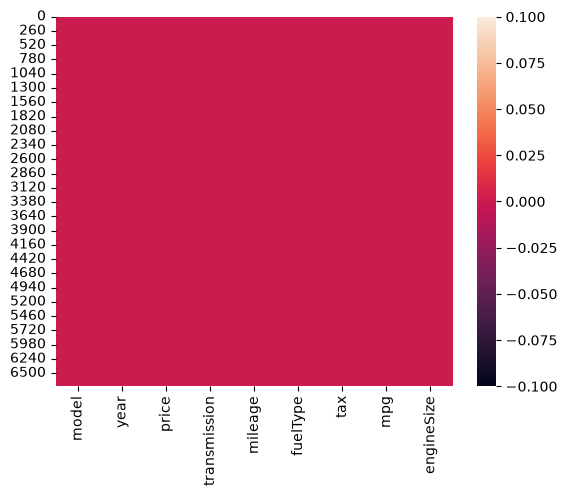

In [8]:
sns.heatmap(df.isnull())

In [9]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000
mean,2016.748145,12522.391066,22857.413921,94.697240,63.042223,1.471297
std,2.204062,6345.017587,19125.464147,73.880776,15.836710,0.436159
min,1998.000000,850.000000,2.000000,0.000000,2.800000,0.000000
25%,2016.000000,8290.000000,9446.000000,0.000000,55.400000,1.000000
50%,2017.000000,10795.000000,18513.000000,135.000000,62.800000,1.500000
75%,2018.000000,14995.000000,31063.750000,145.000000,69.000000,1.800000
max,2020.000000,59995.000000,174419.000000,565.000000,235.000000,4.500000


#VISUALISASI DATA

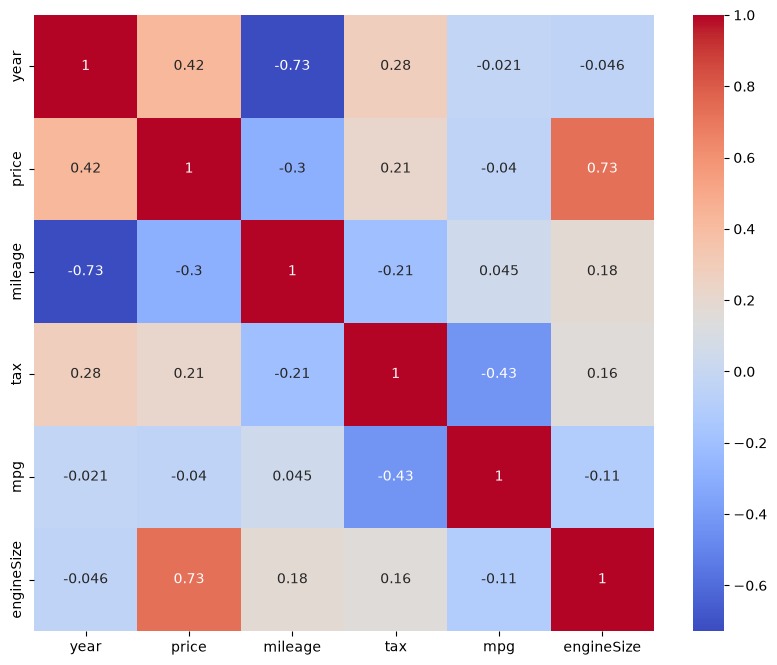

In [11]:
plt.figure(figsize=(10,8))
df_numeric = df.select_dtypes(include=['number'])
sns.heatmap(df_numeric.corr(), annot=True, cmap='coolwarm')
plt.show()

#Jumlah Mobil berdasarkan model

In [13]:
models = df.groupby('model').count()[['tax']].sort_values(by='tax', ascending=True).reset_index()
models = models.rename(columns={'tax': 'number_of_cars'})

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
 [Text(0, 0, ' Verso-S'),
  Text(1, 0, ' Urban Cruiser'),
  Text(2, 0, ' IQ'),
  Text(3, 0, ' Camry'),
  Text(4, 0, ' Supra'),
  Text(5, 0, ' PROACE VERSO'),
  Text(6, 0, ' Land Cruiser'),
  Text(7, 0, ' GT86'),
  Text(8, 0, ' Hilux'),
  Text(9, 0, ' Verso'),
  Text(10, 0, ' Avensis'),
  Text(11, 0, ' Prius'),
  Text(12, 0, ' Corolla'),
  Text(13, 0, ' RAV4'),
  Text(14, 0, ' C-HR'),
  Text(15, 0, ' Auris'),
  Text(16, 0, ' Aygo'),
  Text(17, 0, ' Yaris')])

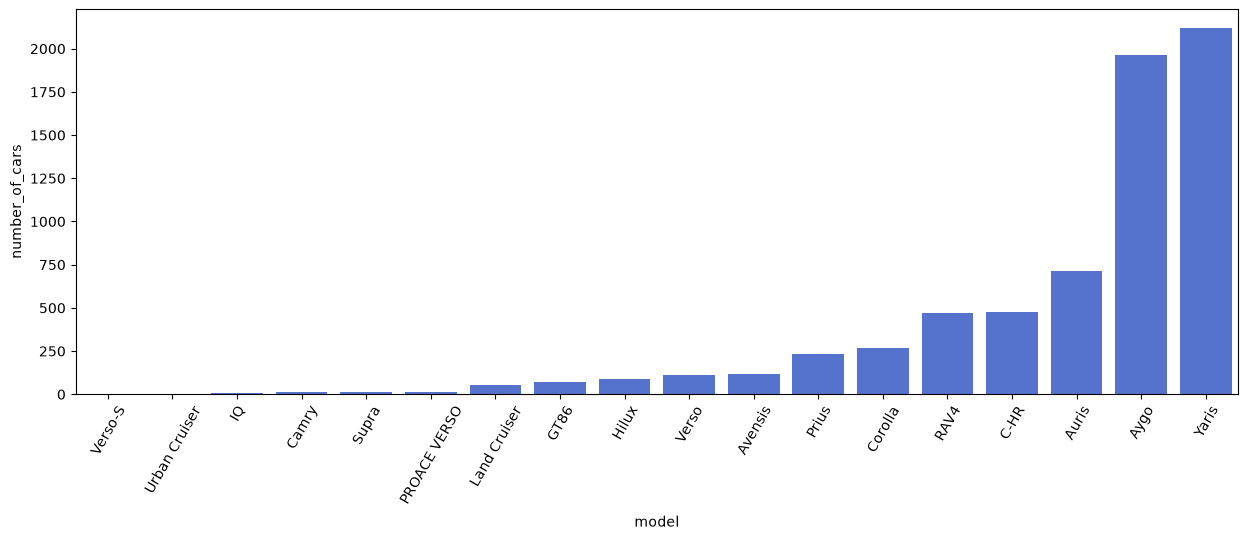

In [14]:
fig = plt.figure(figsize=(15, 5))
sns.barplot(x=models['model'], y=models['number_of_cars'], color='royalblue')
plt.xticks(rotation=60)

#ukuran mesin

In [15]:
engine = df.groupby('engineSize').count()[['tax']].sort_values(by='tax').reset_index()
engine = engine.rename(columns={'tax': 'count'})

<Axes: xlabel='engineSize', ylabel='count'>

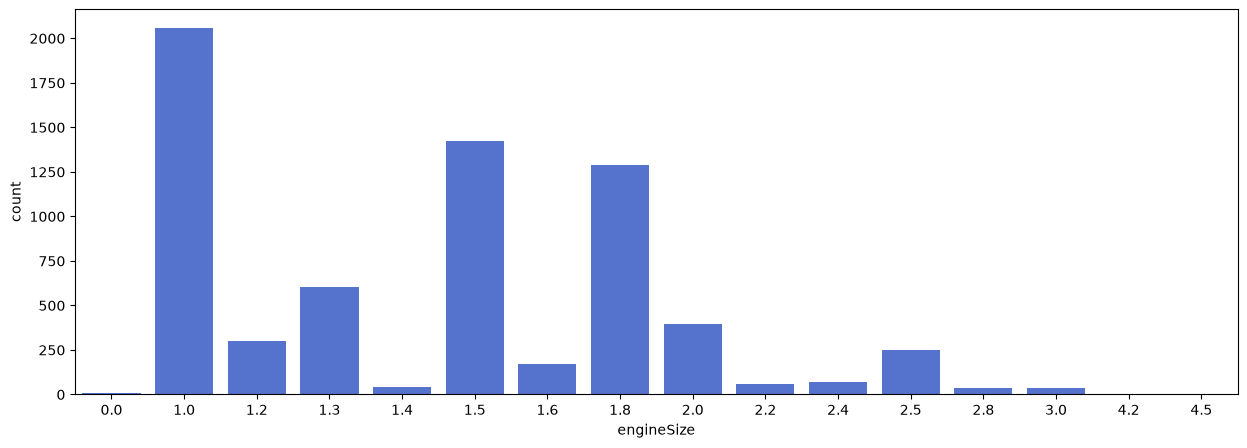

In [16]:
plt.figure(figsize=(15, 5))
sns.barplot(x=engine['engineSize'], y=engine['count'], color='royalblue')

#distribusi mileage

C:\Users\user\AppData\Local\Temp\ipykernel_14184\3423790836.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['mileage'])


<Axes: xlabel='mileage', ylabel='Density'>

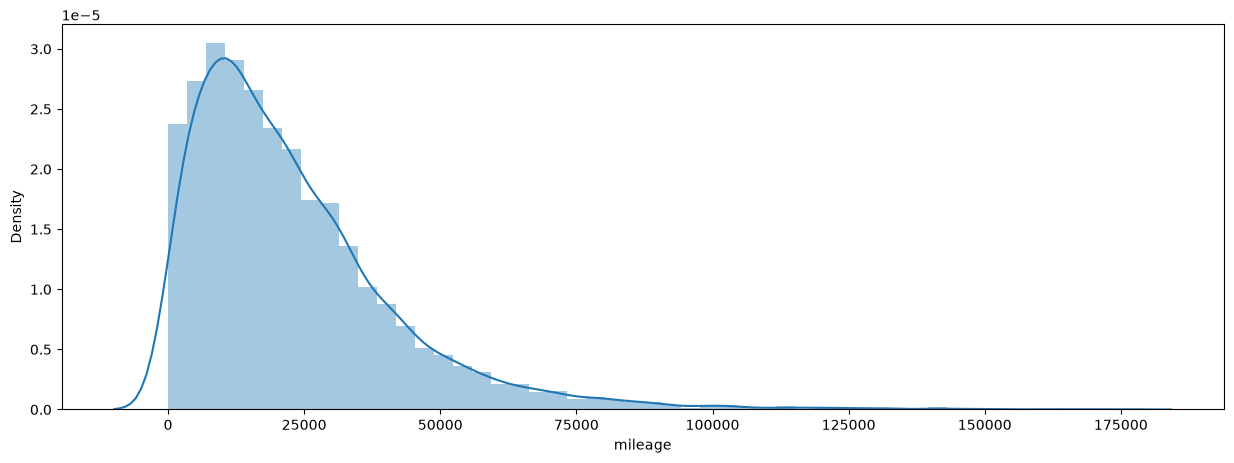

In [17]:
plt.figure(figsize=(15, 5))
sns.distplot(df['mileage'])

#Distribusi harga mobil

<Figure size 1500x500 with 0 Axes>

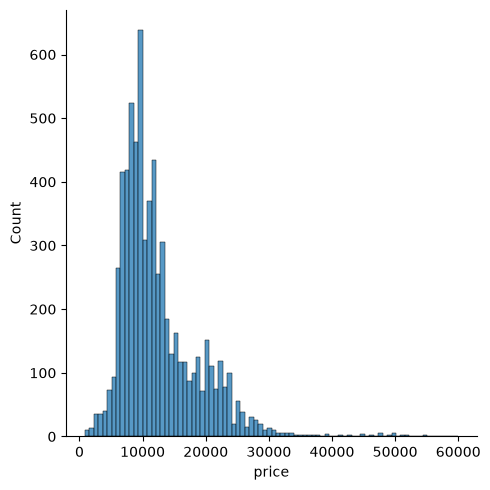

In [18]:
plt.figure(figsize=(15, 5))
sns.displot(df['price'])

#seleksi fitur

In [19]:
features = ['year', 'mileage', 'tax', 'mpg', 'engineSize']
x = df[features]
y = df['price']
x.shape, y.shape   

((6738, 5), (6738,))

#split data training dan data testing

In [33]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y,random_state=70)
y_test.shape 

(1685,)

#MEMBUAT MODEL REGRESI LINIER

In [37]:
from sklearn.linear_model import LinearRegression
Ir = LinearRegression()
Ir.fit(x_train, y_train)
pred = Ir.predict(x_test)

In [38]:
score = Ir.score(x_test, y_test)
print('akurasi model regresi linier =', score)

akurasi model regresi linier = 0.7678983314475174


#membuat inputan model regresi linier

In [39]:
#Year=2019, mileage=50000, tax=145, mpg=30, engineSize=2.2
input_data = np.array([[2019, 50000, 145, 30, 2.2]])

prediction = Ir.predict(input_data)
print('Estimasi harga mobil dalam EUR:', prediction)

Estimasi harga mobil dalam EUR: [19914.77046885]


c:\Users\user\Pictures\data mining C\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


#save model

In [40]:
import pickle

filename = 'estimasi_mobil.sav'
pickle.dump(Ir, open(filename, 'wb'))